# Exercise 57 – A dataset of labelled clusters

**Week 11 · Classification**

1000 two-dimensional 12-atom clusters, each with an energy and one of ten
class labels. Before building a classifier we look at the data: how are the
energies distributed within each class, and what do the clusters look like?

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from comphy import DATA_DIR
from comphy.clusters import plot_cluster
from comphy.plotting import setup_axes

raw = np.loadtxt(DATA_DIR / "labeled_clusters_1000.txt")
positions = raw[:, :24].reshape(-1, 12, 2)
energies = raw[:, 24]
labels = raw[:, 25].astype(int)

print(f"{len(positions)} clusters, labels {sorted(set(labels.tolist()))}")
print("clusters per label:", np.bincount(labels).tolist())

1000 clusters, labels [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
clusters per label: [48, 69, 127, 123, 158, 108, 103, 79, 59, 126]


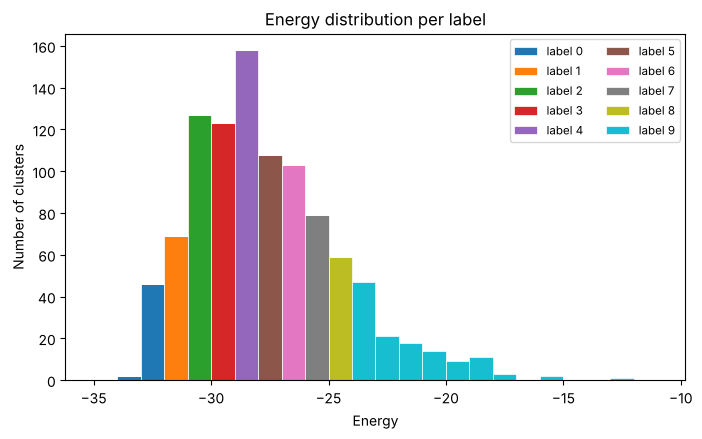

In [2]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.arange(-35, -10, 1)
ax.hist([energies[labels == k] for k in range(10)], bins=bins, stacked=True,
        label=[f"label {k}" for k in range(10)], edgecolor="white", linewidth=0.5)
ax.set(xlabel="Energy", ylabel="Number of clusters", title="Energy distribution per label")
ax.legend(ncol=2, fontsize="small")
plt.show()

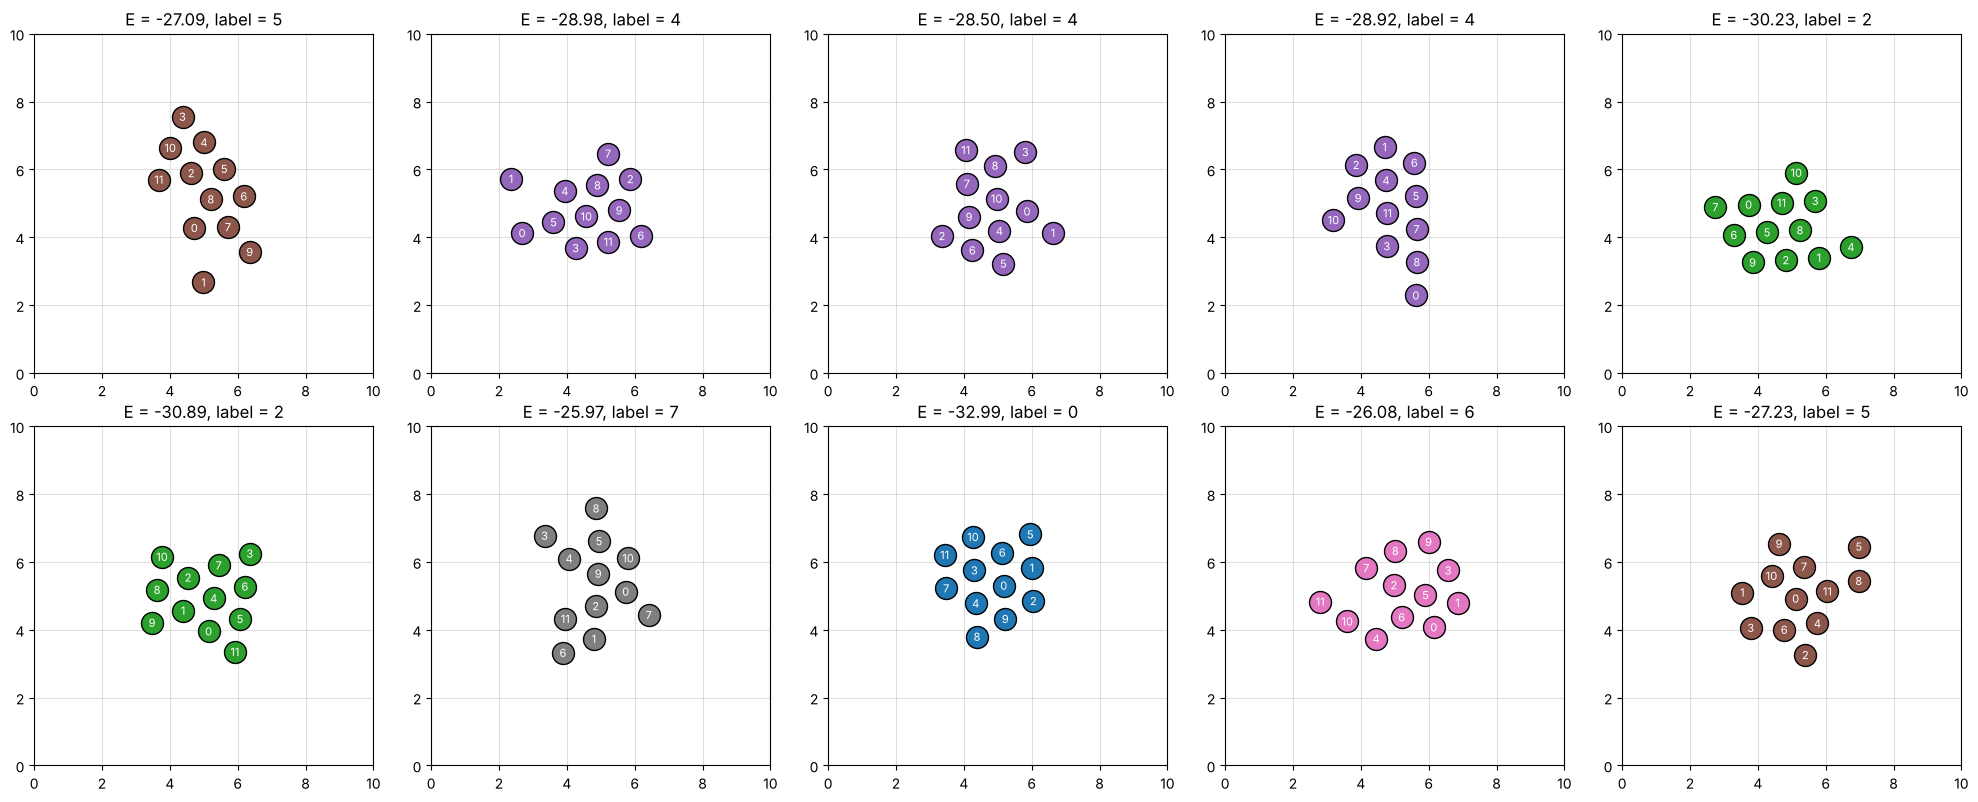

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, pos, e, k in zip(axes.flat, positions, energies, labels):
    plot_cluster(ax, pos, color=f"C{k}", size=250)
    setup_axes(ax, xlim=(0, 10), ylim=(0, 10), zero_lines=False, xlabel=None, ylabel=None,
               title=f"E = {e:.2f}, label = {k}")
fig.tight_layout()
plt.show()